In [1]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("mrwellsdavid/unsw-nb15")
print(os.listdir(path))

train = pd.read_csv(os.path.join(path, "UNSW_NB15_testing-set.csv"))   # 175 341 lignes
test = pd.read_csv(os.path.join(path, "UNSW_NB15_training-set.csv"))   # 82 332 lignes

['NUSW-NB15_features.csv', 'UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv', 'UNSW-NB15_LIST_EVENTS.csv', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']


In [2]:

print("Train :", train.shape)
print("Test  :", test.shape)
train.info()

Train : (175341, 45)
Test  : (82332, 45)
<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              17

In [3]:
train.isnull().sum().sort_values(ascending=False).head(10)

id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
dtype: int64

In [4]:
print("Total valeurs manquantes :", train.isnull().sum().sum())
print()
print(train["service"].value_counts())

Total valeurs manquantes : 0

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64


In [5]:
print(train["label"].value_counts())
print()
print(train["attack_cat"].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


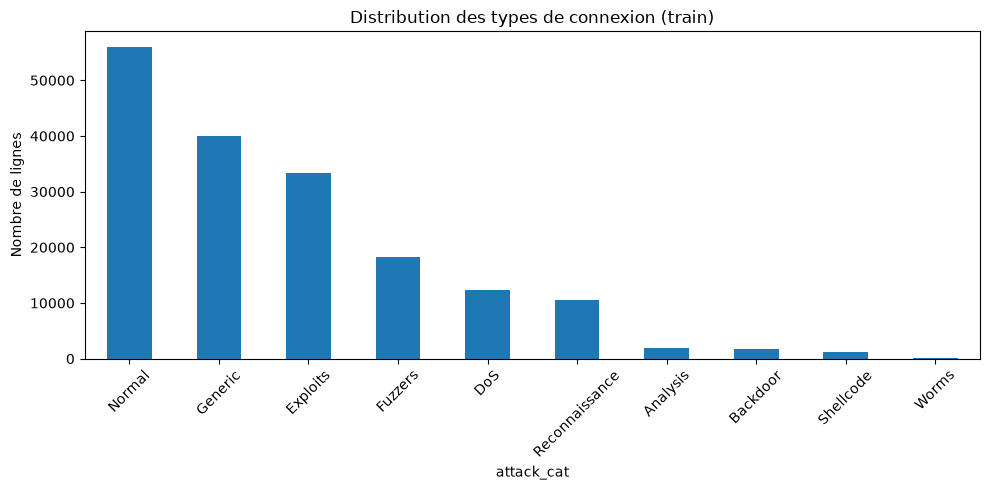

In [6]:
import matplotlib.pyplot as plt

train["attack_cat"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Distribution des types de connexion (train)")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


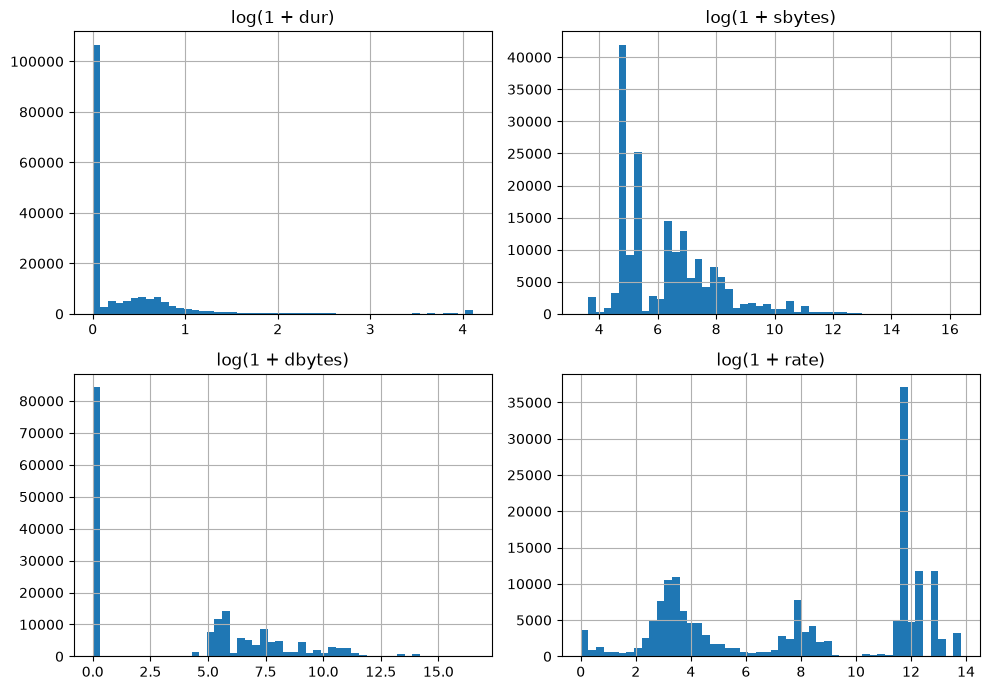

In [8]:
import numpy as np

cols = ["dur", "sbytes", "dbytes", "rate"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, c in zip(axes.flat, cols):
    np.log1p(train[c]).hist(bins=50, ax=ax)
    ax.set_title(f"log(1 + {c})")
plt.tight_layout()
plt.show()

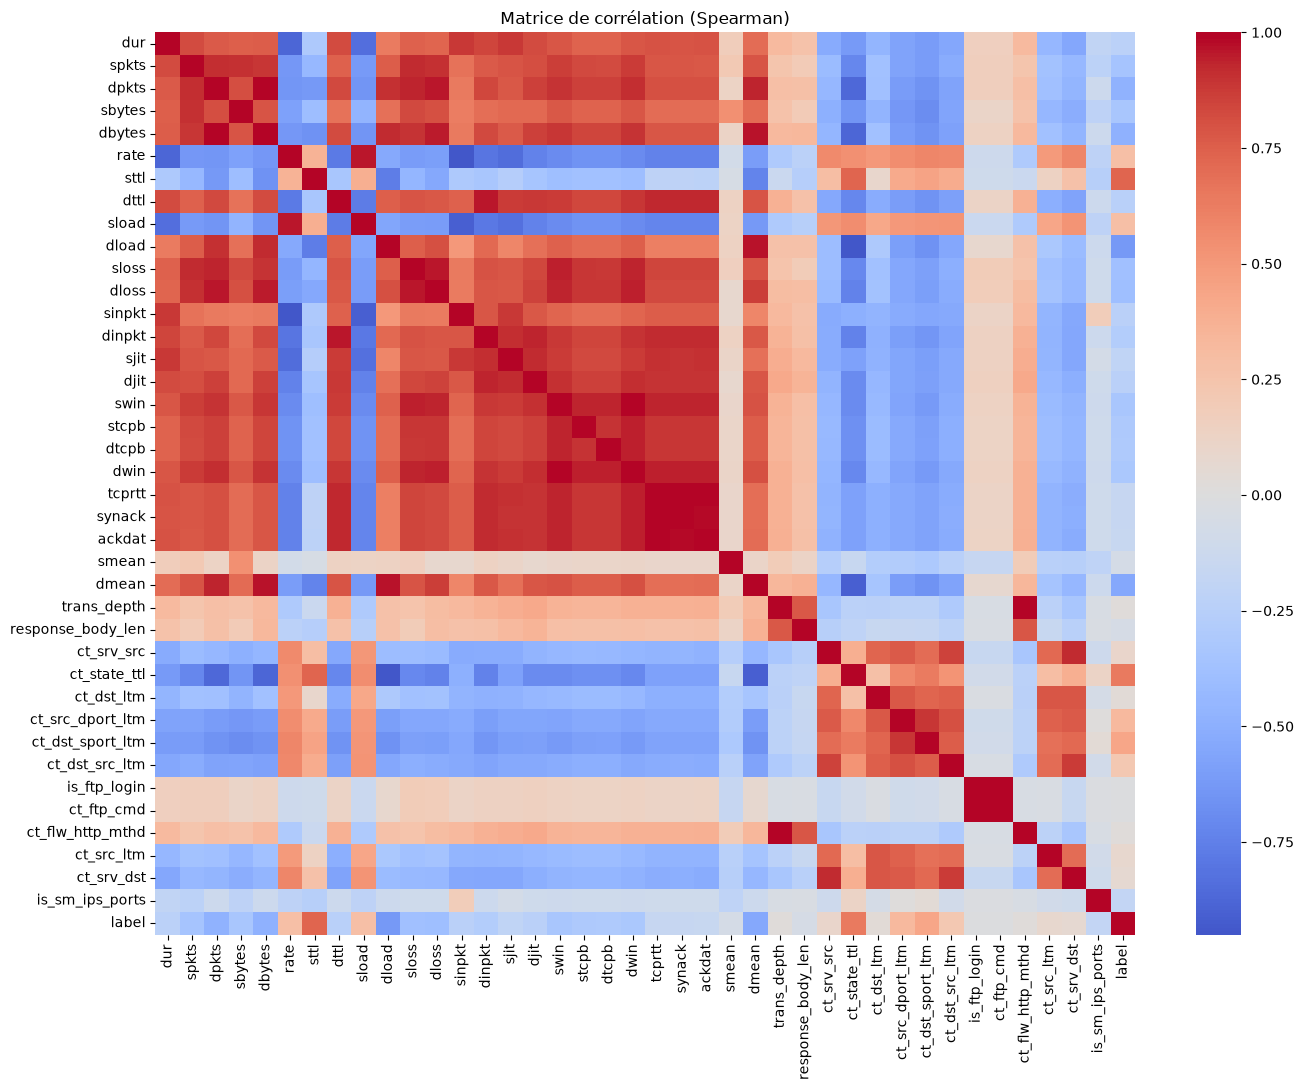

In [9]:
import seaborn as sns

num = train.select_dtypes("number").drop(columns=["id"])
corr = num.corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matrice de corrélation (Spearman)")
plt.tight_layout()
plt.show()

In [10]:
corr["label"].drop("label").sort_values(key=abs, ascending=False).head(10)

sttl                0.732498
ct_state_ttl        0.644469
dload              -0.625768
dmean              -0.546299
dbytes             -0.491295
dpkts              -0.485020
ct_dst_sport_ltm    0.429939
dloss              -0.388440
sloss              -0.380455
spkts              -0.354146
Name: label, dtype: float64

In [11]:
from scipy.stats import mannwhitneyu

for col in ["sttl", "dbytes", "dur"]:
    normal = train.loc[train["label"] == 0, col]
    attaque = train.loc[train["label"] == 1, col]
    stat, p = mannwhitneyu(normal, attaque, alternative="two-sided")
    print(f"{col}: U = {stat:.0f}, p-value = {p:.3e}")
    print(f"   médiane normal = {normal.median():.4f} | médiane attaque = {attaque.median():.4f}")

sttl: U = 792365570, p-value = 0.000e+00
   médiane normal = 31.0000 | médiane attaque = 254.0000
dbytes: U = 5257738892, p-value = 0.000e+00
   médiane normal = 1112.0000 | médiane attaque = 0.0000
dur: U = 4292667482, p-value = 0.000e+00
   médiane normal = 0.0386 | médiane attaque = 0.0000


In [12]:
from scipy.stats import chi2_contingency

table = pd.crosstab(train["service"], train["label"])
chi2, p, dof, expected = chi2_contingency(table)
n = table.values.sum()
v_cramer = (chi2 / (n * (min(table.shape) - 1))) ** 0.5

print(f"Chi2 = {chi2:.1f}, ddl = {dof}, p-value = {p:.3e}")
print(f"V de Cramér = {v_cramer:.3f}")
print("Cases à effectif attendu < 5 :", (expected < 5).sum())

Chi2 = 12985.7, ddl = 12, p-value = 0.000e+00
V de Cramér = 0.272
Cases à effectif attendu < 5 : 1


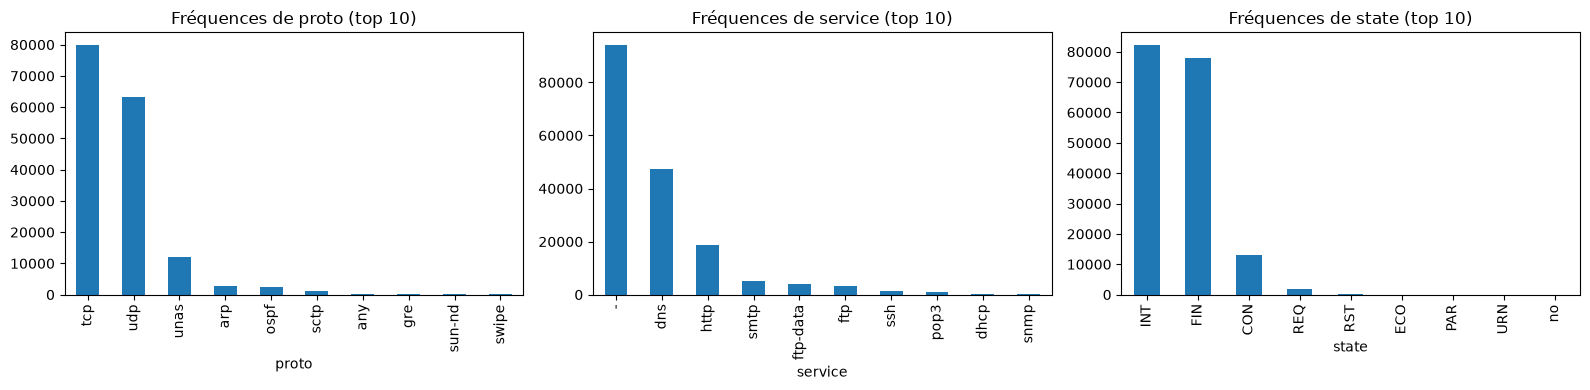

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["proto", "service", "state"]):
    train[col].value_counts().head(10).plot(kind="bar", ax=ax)
    ax.set_title(f"Fréquences de {col} (top 10)")
plt.tight_layout()
plt.show()

In [14]:
for col in ["proto", "service", "state"]:
    print(col, ":", train[col].nunique(), "valeurs différentes")

proto : 133 valeurs différentes
service : 13 valeurs différentes
state : 9 valeurs différentes
